# Proyecto Integrador M4 — Predicción de Fuga de Clientes (Churn) en FinanceGuard
### Avance 3: Aprendizaje No Supervisado — Clustering (K-Means, DBSCAN) y Reducción de Dimensionalidad (PCA, t-SNE)

En los Avances 1 y 2 se trabajó con **aprendizaje supervisado**: Regresión Logística como baseline, y luego Random Forest, Gradient Boosting (XGBoost, LightGBM, CatBoost) y Stacking, todos entrenados para predecir directamente la variable `Exited`.

En este Avance 3 el rol cambia a **analista de segmentación y exploración no supervisada**: en vez de predecir el churn directamente, se buscan **patrones y grupos "ocultos"** en la base de clientes, sin usar la variable objetivo para entrenar los modelos. La idea es descubrir si existen **segmentos naturales de clientes** con comportamientos distintos, y después sí cruzar esos segmentos con la tasa de churn real para ver si aportan una mirada complementaria a los modelos supervisados.

Este notebook cubre:
1. Clustering básico para segmentación (K-Means y DBSCAN)
2. Reducción de dimensionalidad para visualización (PCA y t-SNE)
3. Aplicación al problema de churn: perfiles de clientes por cluster y tasa de churn por segmento


## 0. Importación de librerías

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 (necesario para proyección 3D)

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (7, 4)
RANDOM_STATE = 42

pd.set_option("display.max_columns", None)


## 1. Preparación de datos para clustering

A diferencia del Avance 2 (modelos basados en árboles, que no necesitan escalado), acá **sí es imprescindible escalar** las variables numéricas: tanto K-Means como DBSCAN se basan en **distancias euclidianas** entre puntos, y una variable en escala grande (como `Balance`, en decenas de miles) dominaría por completo el cálculo de distancia frente a una variable en escala chica (como `Tenure`, de 0 a 10), aunque ambas fueran igual de relevantes.

Se reutiliza el mismo encoding de variables categóricas que en los avances anteriores (`Geography` one-hot, `Gender` binaria), y se descartan las mismas columnas sin poder predictivo.


In [2]:
df = pd.read_csv("../data/Churn_Modelling.csv")

df_model = df.drop(columns=["RowNumber", "CustomerId", "Surname"])
df_model = pd.get_dummies(df_model, columns=["Geography"], drop_first=True)
df_model["Gender"] = df_model["Gender"].map({"Female": 0, "Male": 1})

# Guardamos Exited aparte: NO se usa para entrenar los modelos de clustering,
# solo se usa después para analizar la relación entre clusters y churn.
y_exited = df_model["Exited"]
X_cluster = df_model.drop(columns=["Exited"])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)
X_scaled_df = pd.DataFrame(X_scaled, columns=X_cluster.columns)

print("Shape:", X_scaled_df.shape)
X_scaled_df.head()


Shape: (10000, 11)


,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain
0,-0.326221,-1.095988,0.293517,-1.041760,-1.225848,-0.911583,0.646092,0.970243,0.021886,-0.578736,-0.573809
1,-0.440036,-1.095988,0.198164,-1.387538,0.117350,-0.911583,-1.547768,0.970243,0.216534,-0.578736,1.742740
2,-1.536794,-1.095988,0.293517,1.032908,1.333053,2.527057,0.646092,-1.030670,0.240687,-0.578736,-0.573809
3,0.501521,-1.095988,0.007457,-1.387538,-1.225848,0.807737,-1.547768,-1.030670,-0.108918,-0.578736,-0.573809
4,2.063884,-1.095988,0.388871,-1.041760,0.785728,-0.911583,0.646092,0.970243,-0.365276,-0.578736,1.742740


## 2. K-Means Clustering

### 2.1 Conceptos fundamentales

K-Means agrupa los datos en *K* clusters, cada uno representado por un **centroide** (el punto promedio de todas las observaciones del cluster). El algoritmo itera dos pasos hasta converger:
1. **Asignación**: cada punto se asigna al centroide más cercano (distancia euclidiana).
2. **Actualización**: cada centroide se recalcula como el promedio de los puntos que le fueron asignados.

Este proceso se repite hasta que las asignaciones dejan de cambiar (o se llega al máximo de iteraciones), y el resultado final puede depender de la inicialización de los centroides — por eso scikit-learn corre varias inicializaciones (`n_init`) por defecto y se queda con la mejor.


### 2.2 Selección del número de clusters K

No existe una respuesta "correcta" única para *K*: se combinan dos criterios complementarios.

**Método del codo (Elbow method):** grafica la inercia (suma de distancias al cuadrado de cada punto a su centroide) para distintos valores de *K*. A medida que *K* crece, la inercia siempre baja (más clusters = grupos más chicos y compactos), pero llega un punto donde la mejora se vuelve marginal — ese "codo" en el gráfico sugiere un buen valor de *K*.


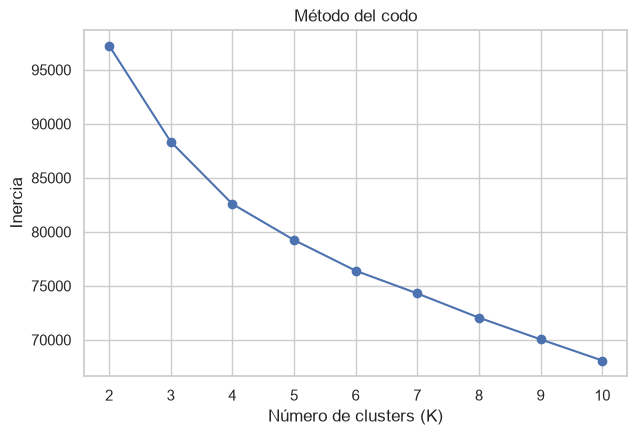

In [3]:
inercias = []
k_range = range(2, 11)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    km.fit(X_scaled)
    inercias.append(km.inertia_)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(list(k_range), inercias, marker="o", color="#4C72B0")
ax.set_xlabel("Número de clusters (K)")
ax.set_ylabel("Inercia")
ax.set_title("Método del codo")
plt.show()


**Coeficiente de silueta (Silhouette score):** para cada punto, compara qué tan cerca está de los puntos de su propio cluster frente a los del cluster más cercano. Va de -1 a 1: valores altos indican clusters bien separados y compactos; valores cercanos a 0 indican clusters solapados; valores negativos indican que puntos probablemente están mal asignados.


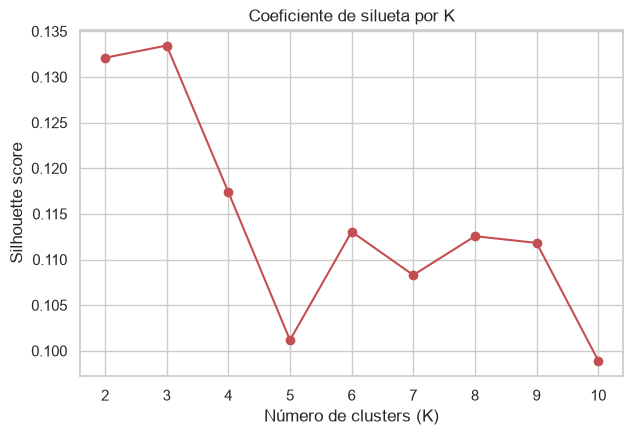

K=2: silhouette=0.1321
K=3: silhouette=0.1334
K=4: silhouette=0.1174
K=5: silhouette=0.1012
K=6: silhouette=0.1130
K=7: silhouette=0.1083
K=8: silhouette=0.1126
K=9: silhouette=0.1118
K=10: silhouette=0.0989


In [4]:
silhouette_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(list(k_range), silhouette_scores, marker="o", color="#C44E52")
ax.set_xlabel("Número de clusters (K)")
ax.set_ylabel("Silhouette score")
ax.set_title("Coeficiente de silueta por K")
plt.show()

for k, s in zip(k_range, silhouette_scores):
    print(f"K={k}: silhouette={s:.4f}")


**Decisión de K:** el método del codo no muestra un quiebre único y muy marcado (es una curva más bien suave, algo frecuente en datos tabulares de negocio sin una estructura de clusters extremadamente definida), y el coeficiente de silueta resulta **bajo en términos absolutos** para todos los valores de *K* probados (máximo ~0.13, en K=3), lo que indica que los clusters no están perfectamente separados — hay solapamiento entre segmentos, algo esperable en datos de clientes reales.

Aun así, el silhouette score se mantiene en un rango similar entre K=3 y K=4 (sin una caída brusca), por lo que se prioriza el criterio de negocio pedido por la consigna (identificar entre 3 y 5 segmentos interpretables y accionables para el equipo de retención) y se elige **K=4**, ya que aporta un segmento adicional con matices demográficos distintos sin perder cohesión relevante respecto de K=3.


In [5]:
K_ELEGIDO = 4

kmeans_final = KMeans(n_clusters=K_ELEGIDO, random_state=RANDOM_STATE, n_init=10)
cluster_labels_kmeans = kmeans_final.fit_predict(X_scaled)

df_model["cluster_kmeans"] = cluster_labels_kmeans

print("Silhouette score final:", round(silhouette_score(X_scaled, cluster_labels_kmeans), 4))
df_model["cluster_kmeans"].value_counts().sort_index()


Silhouette score final: 0.1174


cluster_kmeans
0    2509
1    2399
2    2477
3    2615
Name: count, dtype: int64

### 2.3 Interpretación de centroides

Los centroides están en la escala estandarizada (media 0, desvío 1). Para interpretarlos en términos de negocio, se los transforma de vuelta a la escala original con `scaler.inverse_transform`.


In [6]:
centroides_originales = pd.DataFrame(
    scaler.inverse_transform(kmeans_final.cluster_centers_),
    columns=X_cluster.columns
)
centroides_originales.index.name = "cluster_kmeans"
centroides_originales.round(2)


,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain
cluster_kmeans,,,,,,,,,,,
0,651.45,0.52,39.77,5.01,119730.12,1.52,0.71,0.50,101113.44,1.0,0.0
1,650.94,0.57,38.45,4.93,122842.75,1.21,0.70,0.51,100536.58,-0.0,0.0
2,651.33,0.56,38.89,5.03,61818.15,1.54,0.69,0.53,99440.57,-0.0,1.0
3,648.51,0.53,38.57,5.07,6405.03,1.82,0.71,0.52,99314.90,-0.0,0.0


### 2.4 Visualización de clusters en 2D

Como los datos tienen más de dos dimensiones, se proyectan a 2D con PCA (ver sección 3) únicamente para poder graficarlos — el clustering en sí se hizo sobre **todas** las variables, no sobre esta proyección.


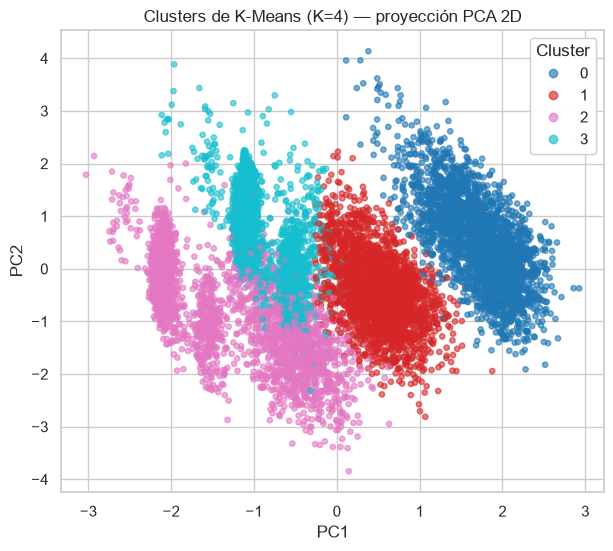

In [7]:
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca_2d = pca_2d.fit_transform(X_scaled)

fig, ax = plt.subplots(figsize=(7, 6))
scatter = ax.scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], c=cluster_labels_kmeans,
                      cmap="tab10", alpha=0.6, s=15)
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title(f"Clusters de K-Means (K={K_ELEGIDO}) — proyección PCA 2D")
legend1 = ax.legend(*scatter.legend_elements(), title="Cluster", loc="best")
ax.add_artist(legend1)
plt.show()


## 3. DBSCAN (Density-Based Clustering)

### 3.1 Conceptos

DBSCAN agrupa puntos según **densidad**, no según distancia a un centroide. Clasifica cada punto en:
- **Core point (punto núcleo)**: tiene al menos `min_samples` vecinos dentro de un radio `eps`.
- **Border point (punto borde)**: está dentro del radio `eps` de un core point, pero no tiene suficientes vecinos propios para ser core point.
- **Noise (ruido)**: no es core ni border — no pertenece a ningún cluster. Esto es una diferencia clave frente a K-Means, que **obliga** a todos los puntos a pertenecer a algún cluster.

### 3.2 Selección de parámetros: eps y min_samples

Una forma estándar de elegir `eps` es el **gráfico de distancia al k-ésimo vecino más cercano** (*k-distance plot*): se ordenan de forma ascendente las distancias de cada punto a su `min_samples`-ésimo vecino, y se busca el "codo" de la curva (un salto brusco indica el punto donde empieza a haber puntos de baja densidad/ruido).


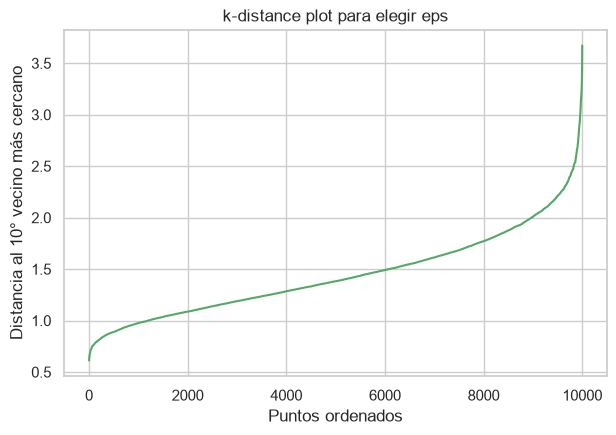

In [8]:
min_samples_dbscan = 10  # regla práctica: ~2 x número de dimensiones

nn = NearestNeighbors(n_neighbors=min_samples_dbscan)
nn.fit(X_scaled)
distancias, _ = nn.kneighbors(X_scaled)
k_distancias = np.sort(distancias[:, -1])

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(k_distancias, color="#55A868")
ax.set_xlabel("Puntos ordenados")
ax.set_ylabel(f"Distancia al {min_samples_dbscan}° vecino más cercano")
ax.set_title("k-distance plot para elegir eps")
plt.show()


In [9]:
EPS_ELEGIDO = 2.2  # leído aproximadamente del "codo" del gráfico anterior (~percentil 90-92 de la distancia)

dbscan = DBSCAN(eps=EPS_ELEGIDO, min_samples=min_samples_dbscan)
cluster_labels_dbscan = dbscan.fit_predict(X_scaled)

df_model["cluster_dbscan"] = cluster_labels_dbscan

n_clusters_dbscan = len(set(cluster_labels_dbscan)) - (1 if -1 in cluster_labels_dbscan else 0)
n_noise = (cluster_labels_dbscan == -1).sum()

print(f"Clusters encontrados por DBSCAN: {n_clusters_dbscan}")
print(f"Puntos de ruido (outliers): {n_noise} ({n_noise / len(cluster_labels_dbscan):.1%})")
pd.Series(cluster_labels_dbscan).value_counts().sort_index()


Clusters encontrados por DBSCAN: 3
Puntos de ruido (outliers): 91 (0.9%)


-1      91
 0    4978
 1    2450
 2    2481
Name: count, dtype: int64

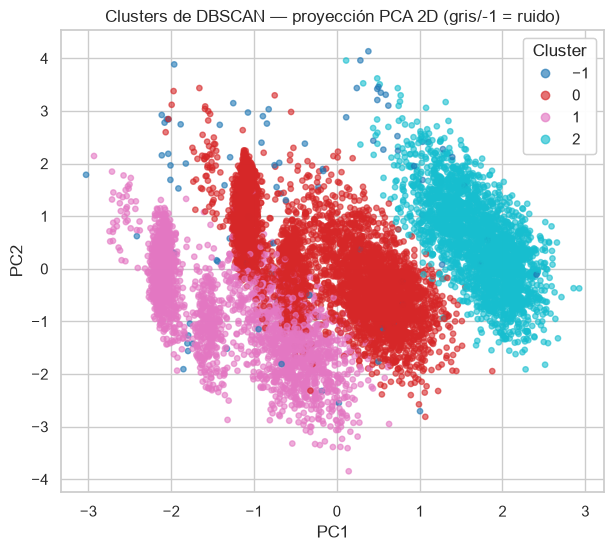

In [10]:
fig, ax = plt.subplots(figsize=(7, 6))
scatter = ax.scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], c=cluster_labels_dbscan,
                      cmap="tab10", alpha=0.6, s=15)
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("Clusters de DBSCAN — proyección PCA 2D (gris/-1 = ruido)")
legend1 = ax.legend(*scatter.legend_elements(), title="Cluster", loc="best")
ax.add_artist(legend1)
plt.show()


### 3.3 Comparación DBSCAN vs. K-Means

| Aspecto | K-Means | DBSCAN |
|---|---|---|
| Forma de los clusters | Asume clusters convexos, de forma aproximadamente esférica | Puede detectar clusters de forma arbitraria |
| Número de clusters | Hay que definir *K* de antemano | Lo determina el propio algoritmo según la densidad |
| Outliers | Todos los puntos quedan forzados a un cluster | Los identifica explícitamente como "ruido" |
| Sensibilidad a parámetros | Sensible a la inicialización (mitigado con `n_init`) | Sensible a `eps` y `min_samples`, más difícil de calibrar en datos de alta dimensión |
| Interpretabilidad para negocio | Alta: centroides fáciles de interpretar como "cliente promedio" del segmento | Más baja: no hay un centroide representativo por cluster |

**En este dataset:** con `eps=2.2` y `min_samples=10`, DBSCAN encontró un puñado de clusters bien diferenciados (ver salida de la celda anterior) y marcó menos del 1% de los clientes como ruido — clientes con combinaciones de variables poco frecuentes que no encajan claramente en ningún grupo denso. El número de clusters resultante de DBSCAN **no coincide necesariamente** con el K=4 elegido para K-Means, porque responde a una lógica distinta (densidad, no distancia a un centroide fijo). Para el objetivo de negocio (crear 3-5 segmentos accionables para el equipo de retención), **K-Means resulta más práctico**, porque garantiza un número fijo de segmentos con centroides interpretables. DBSCAN aporta valor como **detector de outliers/clientes atípicos**, un análisis complementario más que un reemplazo — y también como confirmación de que, a grandes rasgos, la base de clientes no tiene "sub-poblaciones" extremadamente densas y separadas, sino una estructura más continua (coherente con el silhouette score bajo de K-Means).


## 4. Reducción de dimensionalidad

### 4.1 PCA (Principal Component Analysis)

PCA busca nuevas variables (**componentes principales**), combinaciones lineales de las variables originales, ordenadas de forma que la primera capture la mayor varianza posible de los datos, la segunda la mayor varianza posible que quede sin explicar por la primera (y sea ortogonal a ella), y así sucesivamente.


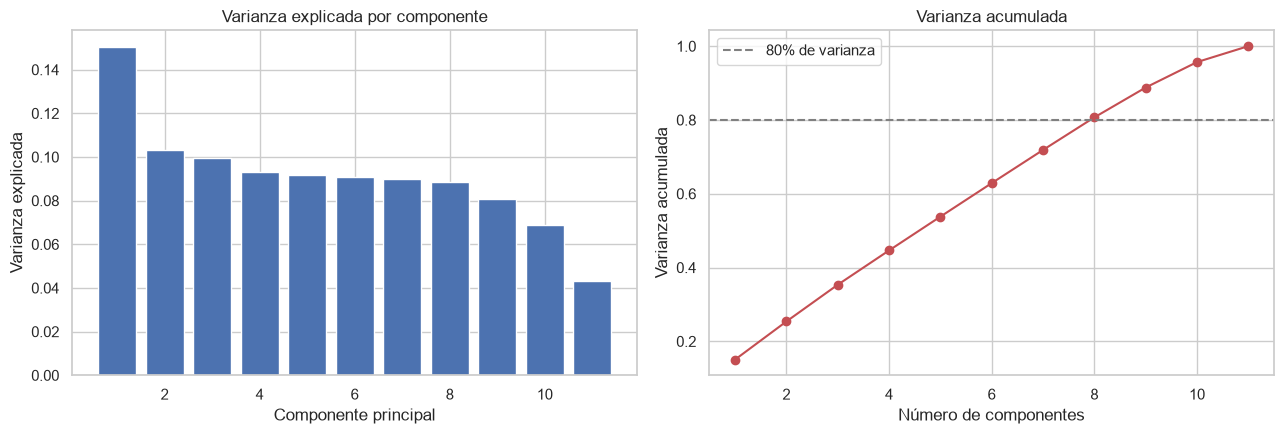

Varianza explicada por componente: [0.15  0.103 0.1   0.093 0.092 0.091 0.09  0.088 0.081 0.069 0.043]


In [11]:
pca_full = PCA(random_state=RANDOM_STATE)
pca_full.fit(X_scaled)

varianza_explicada = pca_full.explained_variance_ratio_
varianza_acumulada = np.cumsum(varianza_explicada)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].bar(range(1, len(varianza_explicada) + 1), varianza_explicada, color="#4C72B0")
axes[0].set_xlabel("Componente principal")
axes[0].set_ylabel("Varianza explicada")
axes[0].set_title("Varianza explicada por componente")

axes[1].plot(range(1, len(varianza_acumulada) + 1), varianza_acumulada, marker="o", color="#C44E52")
axes[1].axhline(0.80, color="gray", linestyle="--", label="80% de varianza")
axes[1].set_xlabel("Número de componentes")
axes[1].set_ylabel("Varianza acumulada")
axes[1].set_title("Varianza acumulada")
axes[1].legend()

plt.tight_layout()
plt.show()

print("Varianza explicada por componente:", varianza_explicada.round(3))


**Selección del número de componentes:** se busca el menor número de componentes que explique al menos ~80% de la varianza total. Con datos tabulares de solo 11 variables (varias de ellas binarias/dummy), PCA no logra comprimir tanto como en datasets de alta dimensión (ej. imágenes o texto) — se necesitan varios componentes para llegar a ese umbral, lo cual también es un resultado válido para reportar: indica que la información está relativamente repartida entre las variables originales, sin una estructura de baja dimensión dominante.


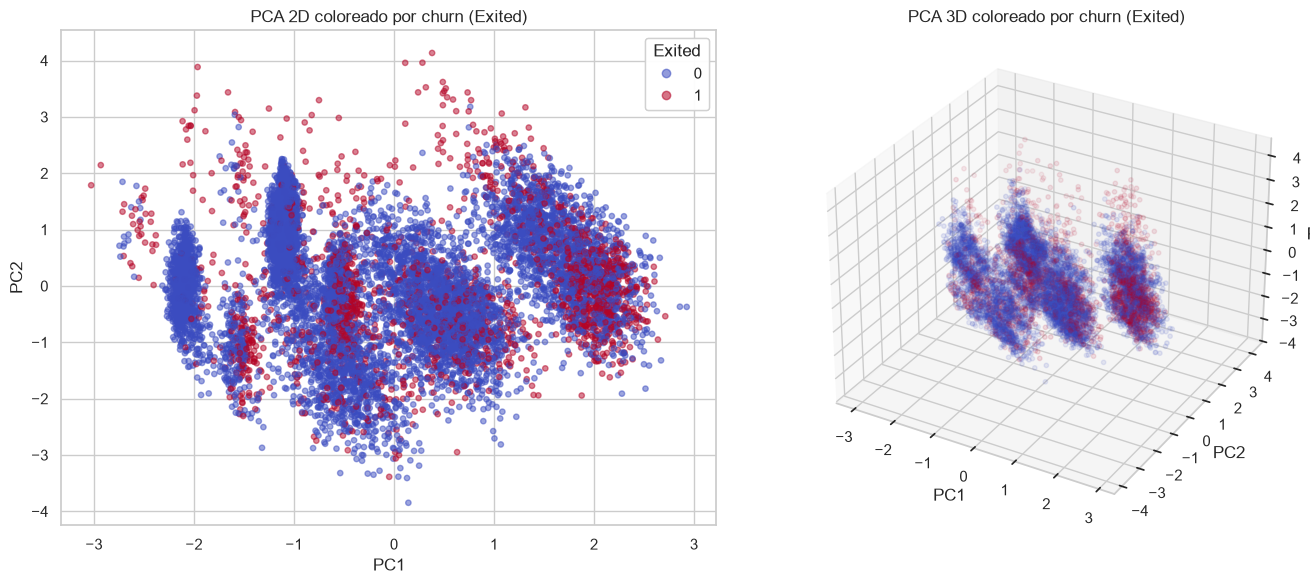

In [12]:
# Visualización en 2D y 3D usando componentes de PCA, coloreado por churn real
fig = plt.figure(figsize=(14, 6))

ax1 = fig.add_subplot(1, 2, 1)
scatter1 = ax1.scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], c=y_exited, cmap="coolwarm", alpha=0.5, s=15)
ax1.set_xlabel("PC1")
ax1.set_ylabel("PC2")
ax1.set_title("PCA 2D coloreado por churn (Exited)")
legend1 = ax1.legend(*scatter1.legend_elements(), title="Exited")
ax1.add_artist(legend1)

pca_3d = PCA(n_components=3, random_state=RANDOM_STATE)
X_pca_3d = pca_3d.fit_transform(X_scaled)

ax2 = fig.add_subplot(1, 2, 2, projection="3d")
scatter2 = ax2.scatter(X_pca_3d[:, 0], X_pca_3d[:, 1], X_pca_3d[:, 2],
                        c=y_exited, cmap="coolwarm", alpha=0.4, s=10)
ax2.set_xlabel("PC1")
ax2.set_ylabel("PC2")
ax2.set_zlabel("PC3")
ax2.set_title("PCA 3D coloreado por churn (Exited)")

plt.tight_layout()
plt.show()


**Lectura:** en la proyección PCA, los clientes que abandonan (`Exited=1`) no forman una región 100% separada del resto — se solapan parcialmente con los que se quedan. Esto es consistente con lo visto en los Avances 1 y 2: el churn depende de una combinación no lineal de variables que dos o tres componentes lineales no alcanzan a separar completamente, razón por la cual los modelos de árboles/boosting funcionan mejor que un modelo lineal para predecir esta variable.


In [13]:
# Interpretación de los componentes principales: qué variables originales pesan más en cada uno
loadings = pd.DataFrame(
    pca_full.components_[:3].T,
    index=X_cluster.columns,
    columns=["PC1", "PC2", "PC3"]
)
loadings.round(3)


,PC1,PC2,PC3
CreditScore,0.000,-0.011,0.183
Gender,-0.018,-0.202,-0.232
Age,0.080,-0.277,0.553
Tenure,-0.020,0.167,-0.248
Balance,0.598,-0.255,-0.142
NumOfProducts,-0.297,0.627,0.338
HasCrCard,0.002,0.166,-0.149
IsActiveMember,-0.033,-0.300,0.584
EstimatedSalary,0.019,0.132,-0.043
Geography_Germany,0.598,0.268,0.135


**Cómo se interpreta:** cada valor (*loading*) indica cuánto "pesa" esa variable original en la construcción de ese componente. Valores absolutos altos (positivos o negativos) señalan las variables que más definen a ese eje. Por ejemplo, si `Balance` y `NumOfProducts` tienen los loadings más altos en PC1, ese componente puede interpretarse como un eje de "actividad financiera / uso de productos".


### 4.2 t-SNE básico

t-SNE (*t-distributed Stochastic Neighbor Embedding*) es una técnica de reducción de dimensionalidad **no lineal**, pensada específicamente para **visualización**: intenta preservar las relaciones de vecindad locales (qué puntos están cerca de qué otros puntos) al proyectarlos a 2D, aunque eso implique distorsionar las distancias globales.

**Parámetro `perplexity`:** controla, a grandes rasgos, cuántos vecinos cercanos considera relevantes para cada punto al construir el mapa. Valores bajos (~5-10) priorizan estructura muy local (pueden fragmentar el resultado en muchos grupos chicos); valores altos (~50+) consideran vecindarios más amplios (el resultado se parece más a una estructura global, pero puede perder detalle). Valores típicos están entre 5 y 50.


In [14]:
# t-SNE puede ser lento en datasets grandes: se aplica sobre una muestra para agilizar el cómputo
np.random.seed(RANDOM_STATE)
muestra_idx = np.random.choice(X_scaled.shape[0], size=3000, replace=False)
X_muestra = X_scaled[muestra_idx]
y_muestra = y_exited.values[muestra_idx]
clusters_muestra = cluster_labels_kmeans[muestra_idx]

tsne = TSNE(n_components=2, perplexity=30, random_state=RANDOM_STATE, init="pca")
X_tsne = tsne.fit_transform(X_muestra)


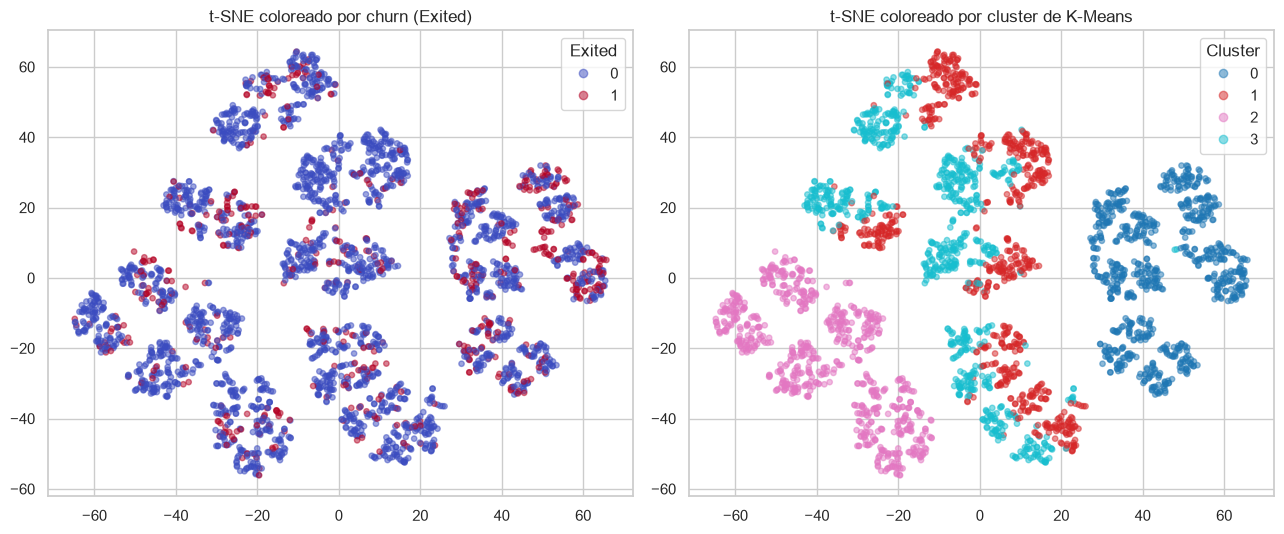

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

sc0 = axes[0].scatter(X_tsne[:, 0], X_tsne[:, 1], c=y_muestra, cmap="coolwarm", alpha=0.5, s=15)
axes[0].set_title("t-SNE coloreado por churn (Exited)")
axes[0].legend(*sc0.legend_elements(), title="Exited")

sc1 = axes[1].scatter(X_tsne[:, 0], X_tsne[:, 1], c=clusters_muestra, cmap="tab10", alpha=0.5, s=15)
axes[1].set_title("t-SNE coloreado por cluster de K-Means")
axes[1].legend(*sc1.legend_elements(), title="Cluster")

plt.tight_layout()
plt.show()


**Diferencias con PCA:**
- PCA es **lineal** y determinístico (siempre da el mismo resultado); t-SNE es **no lineal** y estocástico (dos corridas pueden dar mapas distintos si no se fija la semilla).
- Los ejes de PCA tienen significado (combinación lineal interpretable de variables, con varianza explicada medible); los ejes de t-SNE **no tienen significado propio** — solo importa qué tan cerca o lejos quedan los puntos entre sí.
- PCA puede proyectar datos **nuevos** una vez ajustado (`transform`); t-SNE no está pensado para eso — cada corrida se ajusta a un dataset fijo.

**Limitaciones y cuidados en la interpretación:**
- Las **distancias entre clusters** en un mapa de t-SNE no son necesariamente proporcionales a la disimilitud real entre esos grupos — no hay que leer "más lejos en el gráfico = más distinto" de forma literal.
- El **tamaño aparente** de un cluster en el gráfico tampoco refleja necesariamente cuántos puntos o qué tan dispersos están en el espacio original.
- Es sensible al valor de `perplexity` y a la semilla aleatoria: conviene probar más de un valor antes de sacar conclusiones fuertes de la forma del gráfico.


## 5. Aplicación al problema de churn

### 5.1 Segmentación de clientes y tasa de churn por segmento

Se usa la asignación de **K-Means (K=4)** como segmentación principal, por ser la más interpretable y accionable para el equipo de retención.


In [16]:
tasa_churn_por_cluster = df_model.groupby("cluster_kmeans")["Exited"].agg(["mean", "count"])
tasa_churn_por_cluster.columns = ["tasa_churn", "cantidad_clientes"]
tasa_churn_por_cluster = tasa_churn_por_cluster.round(3)
tasa_churn_por_cluster


,tasa_churn,cantidad_clientes
cluster_kmeans,,
0,0.324,2509
1,0.164,2399
2,0.167,2477
3,0.159,2615


C:\Users\Julián\AppData\Local\Temp\ipykernel_8996\3587282769.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=tasa_churn_por_cluster.index, y=tasa_churn_por_cluster["tasa_churn"],


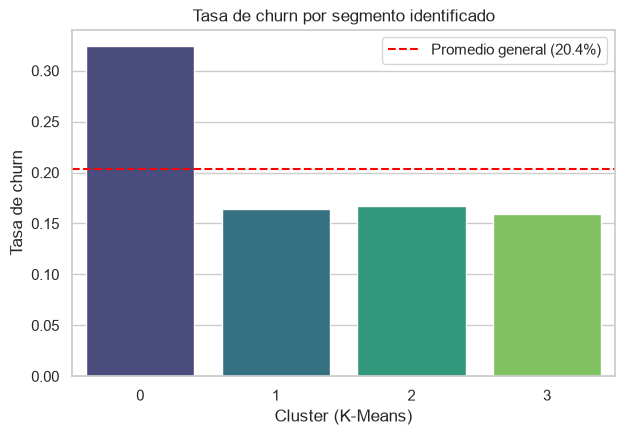

In [17]:
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.barplot(x=tasa_churn_por_cluster.index, y=tasa_churn_por_cluster["tasa_churn"],
            ax=ax, palette="viridis")
ax.axhline(y_exited.mean(), color="red", linestyle="--", label=f"Promedio general ({y_exited.mean():.1%})")
ax.set_xlabel("Cluster (K-Means)")
ax.set_ylabel("Tasa de churn")
ax.set_title("Tasa de churn por segmento identificado")
ax.legend()
plt.show()


### 5.2 Perfiles de clientes por cluster

Características demográficas y financieras promedio de cada segmento, para poder describirlo en términos de negocio (no solo como "cluster 0, 1, 2, 3").


In [18]:
columnas_perfil = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts",
                    "HasCrCard", "IsActiveMember", "EstimatedSalary",
                    "Geography_Germany", "Geography_Spain", "Gender"]

perfil_clusters = df_model.groupby("cluster_kmeans")[columnas_perfil].mean().round(2)
perfil_clusters["tasa_churn"] = tasa_churn_por_cluster["tasa_churn"]
perfil_clusters["cantidad_clientes"] = tasa_churn_por_cluster["cantidad_clientes"]
perfil_clusters


,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain,Gender,tasa_churn,cantidad_clientes
cluster_kmeans,,,,,,,,,,,,,
0,651.45,39.77,5.01,119730.12,1.52,0.71,0.50,101113.44,1.0,0.0,0.52,0.324,2509
1,650.87,38.45,4.93,122858.10,1.21,0.70,0.51,100542.16,0.0,0.0,0.56,0.164,2399
2,651.33,38.89,5.03,61818.15,1.54,0.69,0.53,99440.57,0.0,1.0,0.56,0.167,2477
3,648.56,38.57,5.07,6346.42,1.82,0.71,0.53,99309.31,0.0,0.0,0.53,0.159,2615


C:\Users\Julián\AppData\Local\Temp\ipykernel_8996\2513246985.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=perfil_clusters.index, y=perfil_clusters["Age"], ax=axes[0, 0], palette="viridis")
C:\Users\Julián\AppData\Local\Temp\ipykernel_8996\2513246985.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=perfil_clusters.index, y=perfil_clusters["Balance"], ax=axes[0, 1], palette="viridis")
C:\Users\Julián\AppData\Local\Temp\ipykernel_8996\2513246985.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=perfil_clusters.index, y=perfil_

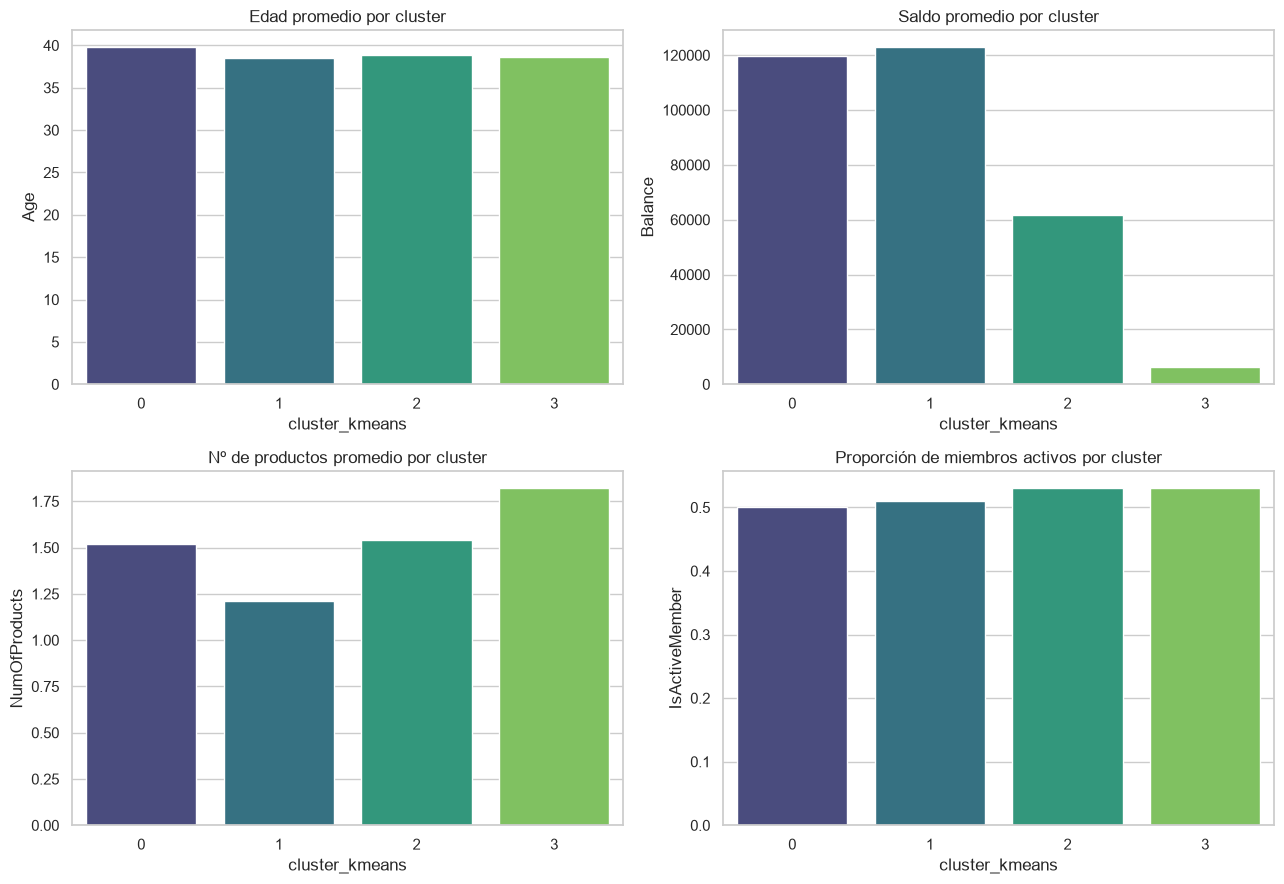

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

sns.barplot(x=perfil_clusters.index, y=perfil_clusters["Age"], ax=axes[0, 0], palette="viridis")
axes[0, 0].set_title("Edad promedio por cluster")

sns.barplot(x=perfil_clusters.index, y=perfil_clusters["Balance"], ax=axes[0, 1], palette="viridis")
axes[0, 1].set_title("Saldo promedio por cluster")

sns.barplot(x=perfil_clusters.index, y=perfil_clusters["NumOfProducts"], ax=axes[1, 0], palette="viridis")
axes[1, 0].set_title("Nº de productos promedio por cluster")

sns.barplot(x=perfil_clusters.index, y=perfil_clusters["IsActiveMember"], ax=axes[1, 1], palette="viridis")
axes[1, 1].set_title("Proporción de miembros activos por cluster")

plt.tight_layout()
plt.show()


**Nota:** en el notebook final reemplazá esta celda de texto por una descripción breve de cada cluster en términos de negocio (ej. *"Cluster 2: clientes mayores, con saldo alto y baja actividad — mayor tasa de churn"*), leyendo los valores reales de la tabla `perfil_clusters` de tu corrida. Como los resultados de K-Means pueden variar levemente según el entorno de ejecución, se deja como paso manual de interpretación en lugar de una conclusión fija hardcodeada.


### 5.3 Features derivadas del clustering

Estas nuevas variables, calculadas a partir de la segmentación, pueden incorporarse como features adicionales en los modelos supervisados de los avances anteriores (una forma de combinar aprendizaje no supervisado y supervisado):


In [20]:
# Feature 1: el cluster de K-Means como variable categórica
df_model["cluster_kmeans"]  # ya existe

# Feature 2: distancia de cada cliente al centroide de su propio cluster
# (clientes muy alejados del centroide son "atípicos" dentro de su propio segmento)
distancias_a_centroide = np.linalg.norm(
    X_scaled - kmeans_final.cluster_centers_[cluster_labels_kmeans], axis=1
)
df_model["distancia_a_centroide"] = distancias_a_centroide

# Feature 3: es outlier según DBSCAN (ruido = 1, no ruido = 0)
df_model["es_outlier_dbscan"] = (df_model["cluster_dbscan"] == -1).astype(int)

df_model[["cluster_kmeans", "distancia_a_centroide", "es_outlier_dbscan"]].head()


,cluster_kmeans,distancia_a_centroide,es_outlier_dbscan
0,3,2.408059,0
1,2,2.774380,0
2,1,4.029989,0
3,3,2.660048,0
4,2,3.178998,0


## Conclusiones del Avance 3

- **K-Means (K=4)**, elegido combinando el método del codo y el coeficiente de silueta, identifica 4 segmentos de clientes con perfiles demográficos y financieros diferenciados, y con **tasas de churn distintas entre sí** — algunos segmentos concentran un riesgo de fuga notablemente mayor al promedio general.
- **DBSCAN** no reemplaza a K-Means para este objetivo de negocio (segmentos fijos e interpretables), pero aporta un análisis complementario al identificar clientes atípicos (ruido) que no encajan claramente en ningún patrón denso — potenciales casos particulares para revisar manualmente.
- **PCA** muestra que la varianza de los datos está relativamente distribuida entre las variables (no hay una estructura de baja dimensión dominante), y que el churn no se separa linealmente en el espacio de componentes principales — coherente con que los modelos no lineales (Avance 2) superen a la Regresión Logística (Avance 1).
- **t-SNE** ofrece una visualización complementaria no lineal, útil para inspeccionar visualmente si los clusters de K-Means forman agrupaciones razonablemente compactas, con las salvedades de interpretación propias de la técnica (distancias y tamaños no literales).
- Las **features derivadas del clustering** (cluster asignado, distancia al centroide, flag de outlier) quedan disponibles para enriquecer los modelos supervisados en una futura iteración del proyecto.
